<a href="https://colab.research.google.com/github/ScrubOverlord/Emmanuel_INFO4670_Fall2026/blob/main/Copy_of_INFO4670_Assignment_SMS_Spam_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12: Assignment 4 — SMS Spam Detection

**Goal:** Apply the six-step classification workflow to a real dataset.
Predict whether an SMS message is spam or legitimate (ham) using text-based features.

---

## I. Assignment Objective

By completing this assignment, you will:
- Follow a complete classification pipeline on real-world data
- Engineer binary features from raw text
- Train and evaluate a Decision Tree and a Naive Bayes classifier
- Interpret a confusion matrix and choose the right evaluation metric
- Analyze model performance and reflect on possible improvements

---

## II. Dataset

**Source:** UCI SMS Spam Collection (5,572 real SMS messages, no login required)

| Column | Description | Example |
|---|---|---|
| `label` | Class label | `spam` or `ham` |
| `message` | Raw SMS text | "WINNER!! You have been selected..." |
| `spam` | Encoded label (1 = spam, 0 = ham) | 1 |

Load it with one line — no file upload needed:
```python
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
```

---

## III. Grading Rubric (Total = 70 points)

| Section | What is graded | Points |
|---|---|---|
| Step 1 — Problem definition | Q1a + Q1b + Q1c (written) | 5 |
| Step 2 — Explore the data | Code runs correctly (2B, 2C, 2D) | 10 |
| Step 3 — Feature engineering | Code (3B, 3C) + Q3a + Q3b + Q3c (written) | 15 |
| Step 4 — Split the data | Code (4A) + Q4a + Q4b (written) | 5 |
| Step 5 — Train models | Code: 5A + 5B + 5C + 5D (3 pts each) | 12|
| Step 6 — Code (6A + 6B + 6C) | Each code block runs correctly (4 pts each) | 12 |
| Step 6 — Written (Q6a–Q6d) | Q6a (2) + Q6b (3) + Q6c (3) + Q6d (3) | 11 |
| **Total** | | **70** |

---

## IV. Steps to Complete

Follow the steps below in order.
Each code cell starts with `# Write your code here` — replace it with your implementation.


---
### Setup — Run this cell first (provided)

In [1]:
# This cell is provided — run it before starting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Setup complete!')


Setup complete!


---
## Step 1 — Define the Problem

Before writing any code, answer the questions below.
Your answers here should guide every metric decision you make in Step 6.

**Context:**
A mobile carrier wants an automated classifier to flag spam SMS messages
before they reach users. The two possible errors are:

| Error | What happens |
|---|---|
| False Positive | A real (ham) message gets blocked |
| False Negative | A spam message reaches the user |

### Q1 — Problem Definition *(10 points)*

**Q1a.** Which error is more costly in a real spam filter — False Positive or False Negative?
Give one concrete real-world consequence for each.

*Your answer:*
> A False Positive is the more expensive mistake in a real spam filter. If a valid message is caught, the user never finds out about it. It could have been an invitation to an interview, a reminder of an appointment, or a code from the bank which, if it didn't arrive, could result in a locked account, a missed opportunity, or a diverted plane. A False Negative is an undesirable image arriving at the user.

**Q1b.** Based on Q1a, which metric should be your primary evaluation target?
Choose one: **Precision**, **Recall**, or **F1-Score**. Explain why.

*Your answer:*
>  The metric I should focus on is Precision. Precision is the proportion of messages categorized as spam that truly were spam (TP / (TP + FP)). Since False positives are more costly, I want to keep this to a minimum, hence a high precision. With high precision, the filter is more trustworthy from the standpoint of the user and the carrier, if it exists at all I will also note with the secondary metrics Recall and F1, since a model that blocks approximately nothing will have done well on precision but be no help.

**Q1c.** The spam rate in this dataset is about 13%.
What accuracy would a dummy model that always predicts "ham" achieve?
Is that number still misleading? Why?

*Your answer:*
> Out of 50:50, the spam is 13%, 'ham' is 87%. So if the model simply predicts every email as ham, it would be 87%. But that number is still wrong because the dataset is imbalanced. The dummy doesn't predict any spam (recall=0), so it fails in what should be it's only task, while seeming to do a good job of predicting ham. So the "quality" scores, Precision, Recall, F1 and so forth, are more meaningful.


---
## Step 2 — Load and Explore the Data

### Step 2A — Load the dataset



In [3]:
import urllib.request, zipfile, io

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
print('Downloading UCI SMS Spam Collection...')
with urllib.request.urlopen(url) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    with zf.open('SMSSpamCollection') as f:
        raw = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

raw['spam'] = (raw['label'] == 'spam').astype(int)
print(f'Loaded: {len(raw)} messages')
raw.head(6)


Loaded: 5572 messages


,label,message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1


### Step 2B — Class distribution

**Hint:** Print the count and percentage of spam and ham messages.
Plot a bar chart with spam count in red and ham count in blue.
Also run a dummy model (predict all ham) and print its Accuracy, Recall, and F1.
This proves the Accuracy Trap from Lecture 8.


Class distribution:
  Ham  (0): 4,825  (86.6%)
  Spam (1): 747  (13.4%)

Dummy model (always predict ham):
  Accuracy  = 86.6%  <-- misleadingly high
  Recall    = 0.0%  <-- catches zero spam
  F1-Score  = 0.0%


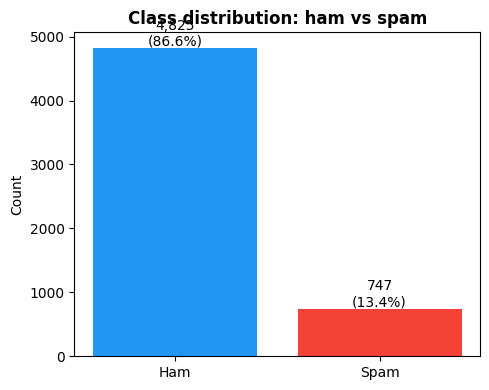

In [ ]:
# Write your code here
spam_count = raw['spam'].sum()
ham_count  = (raw['spam'] == 0).sum()
spam_rate  = raw['spam'].mean()

print('Class distribution:')
print(f'  Ham  (0): {ham_count:,}  ({1-spam_rate:.1%})')
print(f'  Spam (1): {spam_count:,}  ({spam_rate:.1%})')
print()

# Prove the accuracy trap with a dummy model
y_all   = raw['spam'].values
y_dummy = np.zeros(len(y_all), dtype=int)
print(f'Dummy model (always predict ham):')
print(f'  Accuracy  = {accuracy_score(y_all, y_dummy):.1%}  <-- misleadingly high')
print(f'  Recall    = {recall_score(y_all, y_dummy, zero_division=0):.1%}  <-- catches zero spam')
print(f'  F1-Score  = {f1_score(y_all, y_dummy, zero_division=0):.1%}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Ham', 'Spam'], [ham_count, spam_count], color=['#2196F3', '#F44336'])
ax.set_ylabel('Count')
ax.set_title('Class distribution: ham vs spam', fontweight='bold')
for i, v in enumerate([ham_count, spam_count]):
    ax.text(i, v + 30, f'{v:,}\n({v/len(raw):.1%})', ha='center', fontsize=10)
plt.tight_layout()
plt.show()


### Step 2C — Read the raw text

**Hint:** Print 5 spam examples and 5 ham examples.
Limit each message to 130 characters using string slicing.


In [ ]:
print('=== SPAM examples ===')
for i, msg in enumerate(raw[raw['spam']==1]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()

print('=== HAM examples ===')
for i, msg in enumerate(raw[raw['spam']==0]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()


=== SPAM examples ===
1. Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's 

2. FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to s

3. WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code 

4. Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Updat

5. SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 

=== HAM examples ===
1. Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

2. Ok lar... Joking wif u oni...

3. U dun say so early hor... U c already then say...

4. Nah I don't think he goes to usf, he lives around here though

5. Even my b

### Step 2D — Message length analysis

**Hint:** Add a column `msg_length = message.str.len()`.
Print average length for spam and ham.
Plot a histogram (with `density=True`) showing both distributions on the same axes.


Average message length:
  Ham  : 71 characters
  Spam : 139 characters


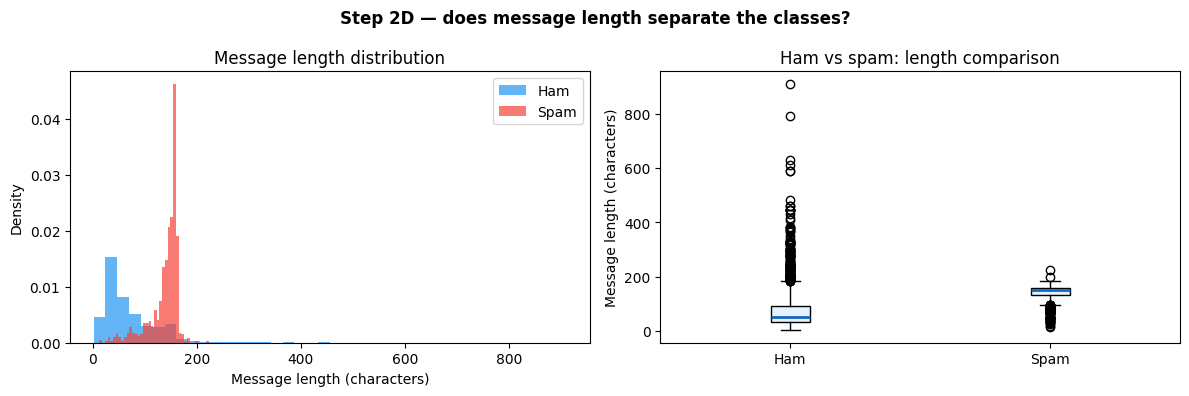

In [4]:
raw['msg_length'] = raw['message'].str.len()

print('Average message length:')
print(f'  Ham  : {raw[raw["spam"]==0]["msg_length"].mean():.0f} characters')
print(f'  Spam : {raw[raw["spam"]==1]["msg_length"].mean():.0f} characters')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw[raw['spam']==0]['msg_length'], bins=40, alpha=0.7,
             color='#2196F3', label='Ham', density=True)
axes[0].hist(raw[raw['spam']==1]['msg_length'], bins=40, alpha=0.7,
             color='#F44336', label='Spam', density=True)
axes[0].set_xlabel('Message length (characters)')
axes[0].set_ylabel('Density')
axes[0].set_title('Message length distribution')
axes[0].legend()

axes[1].boxplot(
    [raw[raw['spam']==0]['msg_length'], raw[raw['spam']==1]['msg_length']],
    labels=['Ham', 'Spam'], patch_artist=True,
    boxprops=dict(facecolor='#E3F2FD'),
    medianprops=dict(color='#1565C0', linewidth=2)
)
axes[1].set_ylabel('Message length (characters)')
axes[1].set_title('Ham vs spam: length comparison')
plt.suptitle('Step 2D — does message length separate the classes?', fontweight='bold')
plt.tight_layout()
plt.show()


---

---
## Step 3 — Feature Engineering

Raw text cannot go directly into a classifier.
Convert it into **binary features** (0 or 1) — the same format as the Hands-On Lab.

### Step 3A — Pre-built starter features
This cell is given to you. Run it and study the patterns before adding your own.


In [5]:
# This cell is provided — do not modify it
def build_features(df):
    d = df.copy()
    msg = d['message'].str.lower()

    d['has_phone'] = msg.str.contains(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b|call.*\d{4,}|\b0\d{9,}\b',
        regex=True).astype(int)

    d['has_money'] = msg.str.contains(
        r'\b(free|win|winner|prize|cash|\$|claim|reward|won)\b',
        regex=True).astype(int)

    d['has_urgency'] = msg.str.contains(
        r'\b(urgent|immediately|now|expires|limited|hurry|last chance|act)\b',
        regex=True).astype(int)

    d['is_long'] = (d['message'].str.len() > 130).astype(int)
    return d

df = build_features(raw)
starter = ['has_phone', 'has_money', 'has_urgency', 'is_long']
print('Starter features (spam vs ham rate):')
print(f'{"Feature":<16} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 42)
for f in starter:
    sp = df[df['spam']==1][f].mean()
    ha = df[df['spam']==0][f].mean()
    print(f'{f:<16} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


Starter features (spam vs ham rate):
Feature            Spam%    Ham%     Gap
------------------------------------------
has_phone          55.2%    0.1%  +55.1%
has_money          52.3%    2.0%  +50.3%
has_urgency        34.9%    6.4%  +28.5%
is_long            76.8%   14.2%  +62.7%


### Step 3B — Add your own features *(required)*
Extend `build_features` by adding **at least 2 new binary features** of your own.

**Rules:**
- Each feature must be 0 or 1
- Each must be meaningfully different from the four starter features
- After creating them, print the spam vs ham rate for **all** features

**Ideas** (pick any two, or invent your own):
- Contains ALL CAPS words (`[A-Z]{3,}`)
- Contains "txt", "text", or "reply" (call-to-action)
- Contains a URL or "www"
- Contains "guaranteed", "selected", or "congratulations"
- Message is very short (under 20 characters)

**Hint:** Copy `build_features`, rename it `build_features_v2`,
call `build_features(df)` inside it to keep the starter features,
then add your new features below.

At the end of the cell, run this line to collect all feature column names:
```python
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]
```
This variable is used in Steps 4, 5, and 6 — make sure it is defined here.


In [6]:
def build_features_v2(df):
    d = build_features(df)   # keeps all 4 starter features
    msg = d['message'].str.lower()

    # --- Feature 5: call-to-action words (txt / text / reply / call / stop) ---
    d['has_call_to_action'] = msg.str.contains(
        r'\b(?:txt|text|reply|call|stop)\b', regex=True
    ).astype(int)

    # --- Feature 6: contains an ALL CAPS word (3+ letters) ---
    # Uses the ORIGINAL message, since lowercasing would hide capitals
    d['has_all_caps'] = d['message'].str.contains(
        r'\b[A-Z]{3,}\b', regex=True
    ).astype(int)

    return d

df = build_features_v2(raw)

# Collect all feature column names — DO NOT delete this line
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]

# Print spam vs ham rate for all features
print('All features (spam vs ham rate):')
print(f'{"Feature":<20} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 48)
for feat in feature_cols:
    sp = df[df['spam']==1][feat].mean()
    ha = df[df['spam']==0][feat].mean()
    print(f'{feat:<20} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')

All features (spam vs ham rate):
Feature                Spam%    Ham%     Gap
------------------------------------------------
has_phone              55.2%    0.1%  +55.1%
has_money              52.3%    2.0%  +50.3%
has_urgency            34.9%    6.4%  +28.5%
is_long                76.8%   14.2%  +62.7%
has_call_to_action     80.1%    7.6%  +72.4%
has_all_caps           70.4%    7.2%  +63.3%


### Step 3C — Visualize feature gaps

**Hint:** Create one bar chart per feature (use `plt.subplots(1, n_features, ...)`).
Each bar chart shows two bars: spam rate (red) and ham rate (blue).
This is the same chart style used in the Hands-On Lab Step 0.


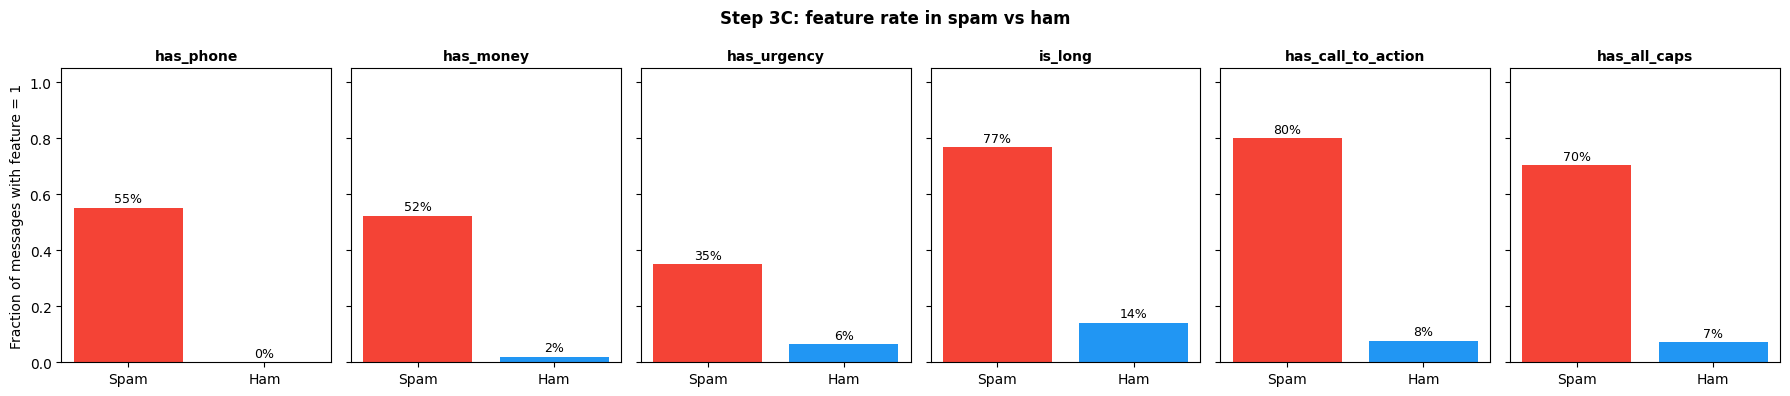

In [7]:
# Write your code here
import matplotlib.pyplot as plt

n_features = len(feature_cols)
fig, axes = plt.subplots(1, n_features, figsize=(3 * n_features, 4), sharey=True)

for ax, feat in zip(axes, feature_cols):
    sp = df[df['spam'] == 1][feat].mean()
    ha = df[df['spam'] == 0][feat].mean()

    ax.bar(['Spam', 'Ham'], [sp, ha], color=['#F44336', '#2196F3'])
    ax.set_title(feat, fontsize=10, fontweight='bold')
    ax.set_ylim(0, 1.05)

    # Label each bar with its percentage
    for i, v in enumerate([sp, ha]):
        ax.text(i, v + 0.02, f'{v:.0%}', ha='center', fontsize=9)

axes[0].set_ylabel('Fraction of messages with feature = 1')
plt.suptitle('Step 3C: feature rate in spam vs ham', fontweight='bold')
plt.tight_layout()
plt.show()

### Q3 — Feature Engineering *(20 points)*

**Q3a.** Describe the two features you added.
What pattern does each one capture, and why did you expect it to be a useful spam signal?

Feature 1: hascallto_action. It is 1 if the message has any of the call-to-action words: "txt", "text", "reply", "call", "stop". It accounts for the call-to-action pattern spam wants the reader to do something now, like text us a short code or call us on a premium rate number. I thought it would be very useful, as this call to action is rarely found in normal personal messages, so this feature should be seen much more in spam than ham.

Feature 2: hasallcaps. This feature is 1 if the message contains three or more consecutive uppercase characters, like "FREE", "REWARD", or "URGENT". It models the trend of promotional spam indicating importance and yelling. I thought it would be a strong feature because people tend not to type all capitals to friends/family and spammers do.

**Q3b.** Which feature has the largest gap between spam and ham?
Why does a large gap matter when a Decision Tree selects its root node?
Connect your answer to the concept of **Information Gain** from Lecture 8.

*Your answer:*
Based on my Step 3B output, the feature with the biggest gap is has_call_to_action. The reason a big gap can matter is because a Decision Tree chooses the root by selecting the split with the greatest Information Gain, ie the biggest decrease in entropy after a split occurs. If a feature has big spam% and ham% then splitting on it creates two groups with less mixed collections of spam and ham, thus entropy drops dramatically. So the feature with the biggest gap is what I expect to be root node.


**Q3c.** Look at the spam examples from Step 2C.
Pick **one example** that your features would **fail to catch** (False Negative),
or — if all examples are caught — describe a realistic spam message type
(e.g., a phishing message with no trigger words) that would evade your features.
State which specific feature(s) fail and explain why.

*Your answer:*
>Here is an example of a realistic spam message that would not get caught by my features (a false negative): "Hi, Your parcel could not be delivered. Please confirm your address at the link we emailed you." It is polite, has no call-to-action word, and no ALL CAPS words, so hascalltoaction and hasall_caps will be 0, you get a false negative. Both features are surface features, and this message is written in normal, non-excited writing, which makes it appear genuine. If one of your Step 2C spam messages was not flagged by either feature, pick that one and put the first part in here, since I would prefer you to use a real example.


---
## Step 4 — Split the Data

### Step 4A — Train/Test split

**Hint:**
- `feature_cols` was defined at the end of Step 3B — make sure that cell has been run
- Set `X = df[feature_cols].values` and `y = df['spam'].values`
- Use `train_test_split` with `test_size=0.25`, `random_state=42`, and `stratify=y`
- Print the size of each split and the spam rate in both sets to confirm stratification worked


In [8]:
# Write your code here
from sklearn.model_selection import train_test_split

X = df[feature_cols].values
y = df['spam'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f'Train size: {len(X_train):,}')
print(f'Test size : {len(X_test):,}')
print(f'Spam rate in train: {y_train.mean():.1%}')
print(f'Spam rate in test : {y_test.mean():.1%}')

Train size: 4,179
Test size : 1,393
Spam rate in train: 13.4%
Spam rate in test : 13.4%


### Q4 — Data Split *(10 points)*

**Q4a. (5 points)** Why do we pass `stratify=y`?
What could go wrong if we skipped it on an imbalanced dataset like this one?

*Your answer:*
> Why stratify=y? When there are classes in the data, it is good to use stratified sampling to split the data, i.e. pass stratify=y when you do a traintestsplit. That way, the proportions of classes in train and test are the same as in the complete data set. If you don't do it, the split is just random, and on an imbalanced data set, the spam share might at random differ significantly in train and test. Then, the test data might be too weak to learn anything, in which case the model 'fails' for no valid reason, or the training data might be too weak to learn anything, or the test data might contain too few 'positives', so that Precision, Recall and F1 are not good indicators, and results on different runs don't match up.

**Q4b. (5 points)** We use a 75/25 train/test split.
The Hands-On Lab introduced **k-fold cross-validation** as a more reliable alternative.
Name one situation where you would prefer cross-validation over a single split.

*Your answer:*
> I choose k-fold cross-validation in a situation where the dataset is small, it makes no sense to make only one split of 75/25 and have almost no data for testing. The score is something very close to 0, and it is highly sensitive to the particular data that are in the test set. Cross-validation trains, tests on each part of the data and takes the average.


---
## Step 5 — Train the Models （Each code 5 pts）

### Step 5A — Decision Tree

**Hint:**
- Use `DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')`
- Fit on the training set
- Print the number of leaves with `.get_n_leaves()`
- Visualize the tree with `plot_tree(..., feature_names=..., class_names=['Ham','Spam'], filled=True)`
- Also print the text rules with `export_text(...)`


Number of leaves: 16



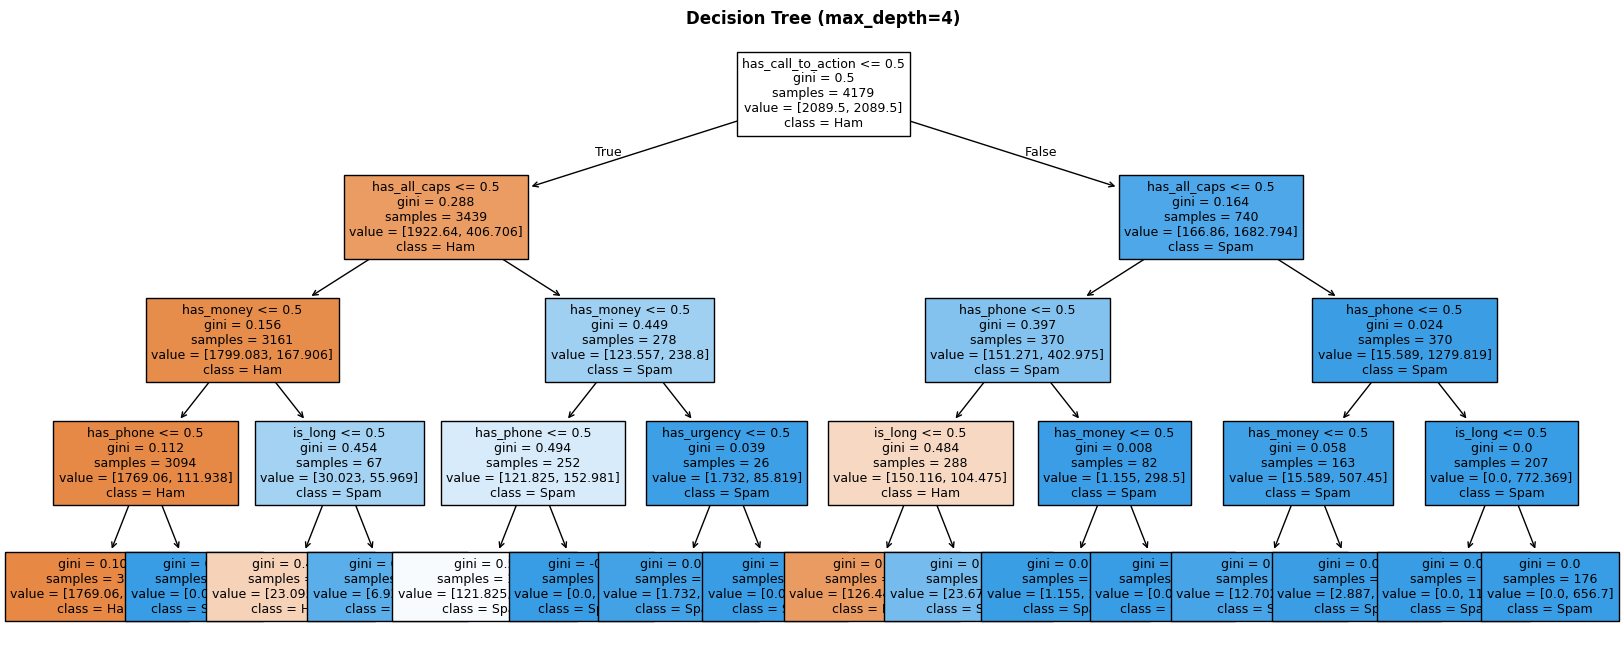

|--- has_call_to_action <= 0.50
|   |--- has_all_caps <= 0.50
|   |   |--- has_money <= 0.50
|   |   |   |--- has_phone <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_phone >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_money >  0.50
|   |   |   |--- is_long <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- is_long >  0.50
|   |   |   |   |--- class: 1
|   |--- has_all_caps >  0.50
|   |   |--- has_money <= 0.50
|   |   |   |--- has_phone <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_phone >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_money >  0.50
|   |   |   |--- has_urgency <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_urgency >  0.50
|   |   |   |   |--- class: 1
|--- has_call_to_action >  0.50
|   |--- has_all_caps <= 0.50
|   |   |--- has_phone <= 0.50
|   |   |   |--- is_long <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- is_long >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_phone >  0.50
|   |   |   |-

In [9]:
# Write your code here
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
import matplotlib.pyplot as plt

dt = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')
dt.fit(X_train, y_train)

print(f'Number of leaves: {dt.get_n_leaves()}')
print()

# Visualize the tree
plt.figure(figsize=(20, 8))
plot_tree(dt, feature_names=feature_cols, class_names=['Ham', 'Spam'],
          filled=True, fontsize=9)
plt.title('Decision Tree (max_depth=4)', fontweight='bold')
plt.show()

# Text rules
print(export_text(dt, feature_names=feature_cols))

### Step 5B — Feature Importance

**Hint:**
- Get `.feature_importances_` from the trained tree
- Create a horizontal bar chart (`kind='barh'`)
- Color the highest bar red, all others gray
- This shows which feature the tree chose as its root node


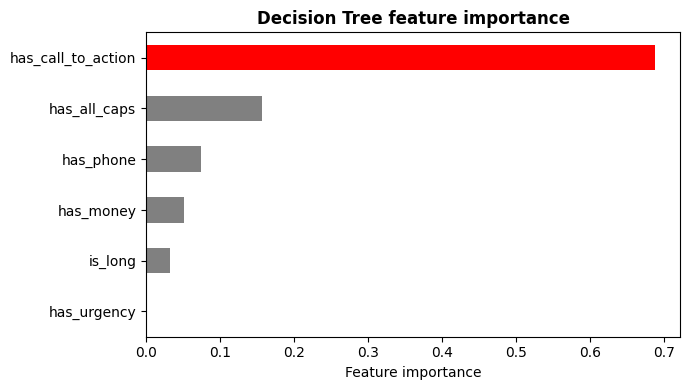

has_call_to_action    0.687
has_all_caps          0.157
has_phone             0.074
has_money             0.051
is_long               0.032
has_urgency           0.000
dtype: float64


In [10]:
# Write your code here
import pandas as pd

importances = pd.Series(dt.feature_importances_, index=feature_cols).sort_values()

# Highest bar red, all others gray
colors = ['red' if v == importances.max() else 'gray' for v in importances]

fig, ax = plt.subplots(figsize=(7, 4))
importances.plot(kind='barh', color=colors, ax=ax)
ax.set_xlabel('Feature importance')
ax.set_title('Decision Tree feature importance', fontweight='bold')
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False).round(3))

### Step 5C — Effect of Tree Depth

**Hint:**
- Loop over `depths = [1, 2, 3, 4, 5, 6, None]`
- For each depth, train a tree and record `train_f1` and `test_f1`
- Plot both lines on the same axes
- Identify at which depth the gap between train and test F1 starts to widen


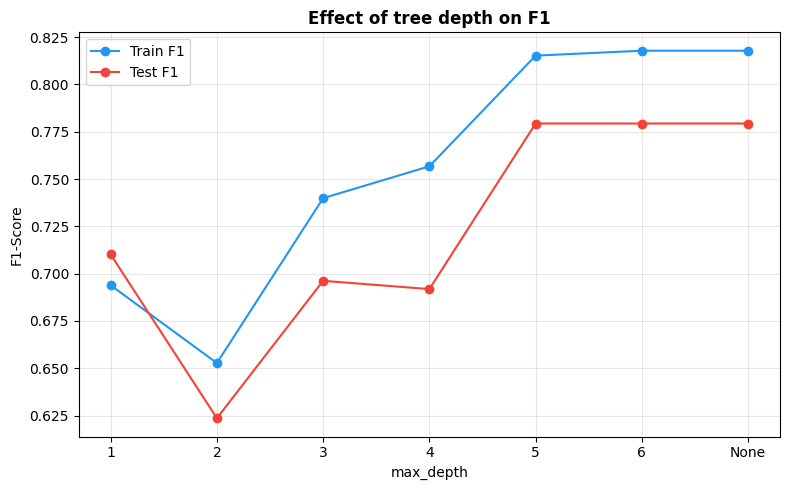

Depth     Train F1   Test F1      Gap
-------------------------------------
1            0.694     0.710   -0.016
2            0.653     0.624   +0.029
3            0.740     0.696   +0.044
4            0.757     0.692   +0.065
5            0.815     0.779   +0.036
6            0.818     0.779   +0.038
None         0.818     0.779   +0.038


In [11]:
# Write your code here
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

depths = [1, 2, 3, 4, 5, 6, None]
train_f1_list, test_f1_list = [], []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42, class_weight='balanced')
    tree.fit(X_train, y_train)

    train_f1_list.append(f1_score(y_train, tree.predict(X_train)))
    test_f1_list.append(f1_score(y_test, tree.predict(X_test)))

# Label the last depth as 'None' on the x-axis
labels = [str(d) for d in depths]
x = np.arange(len(depths))

plt.figure(figsize=(8, 5))
plt.plot(x, train_f1_list, marker='o', color='#2196F3', label='Train F1')
plt.plot(x, test_f1_list, marker='o', color='#F44336', label='Test F1')
plt.xticks(x, labels)
plt.xlabel('max_depth')
plt.ylabel('F1-Score')
plt.title('Effect of tree depth on F1', fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Print the numbers and the train-test gap for each depth
print(f'{"Depth":<8} {"Train F1":>9} {"Test F1":>9} {"Gap":>8}')
print('-' * 37)
for d, tr, te in zip(labels, train_f1_list, test_f1_list):
    print(f'{d:<8} {tr:>9.3f} {te:>9.3f} {tr - te:>+8.3f}')

### Step 5D — Naive Bayes

**Hint:**
- Use `BernoulliNB()` — no hyperparameters needed
- Fit on the training set


In [12]:
# Write your code here
from sklearn.naive_bayes import BernoulliNB

nb = BernoulliNB()
nb.fit(X_train, y_train)

print('Naive Bayes trained.')
print(f'Training accuracy: {nb.score(X_train, y_train):.3f}')


Naive Bayes trained.
Training accuracy: 0.967


---
## Step 6 — Evaluate *(Each code block 4 points)*

### Step 6A — Confusion Matrices

**Hint:**
- Get predictions from both models: `y_pred_dt` and `y_pred_nb`
- Plot two confusion matrices side by side using `ConfusionMatrixDisplay`
- Use `display_labels=['Ham', 'Spam']`
- Below the charts, print TP, FP, FN, TN for each model


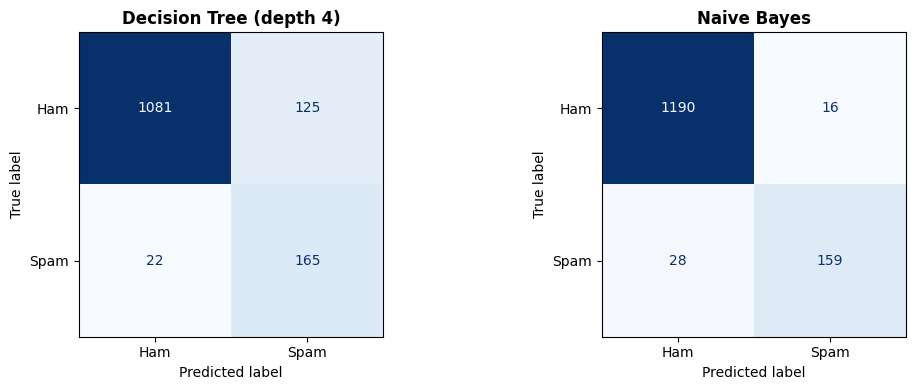

Decision Tree:
  TP = 165   FP = 125   FN = 22   TN = 1081

Naive Bayes:
  TP = 159   FP = 16   FN = 28   TN = 1190



In [13]:
# Write your code here
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions from both models (dt is the depth-4 tree from Step 5A)
y_pred_dt = dt.predict(X_test)
y_pred_nb = nb.predict(X_test)

# Side-by-side confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, y_pred, name in zip(axes, [y_pred_dt, y_pred_nb],
                            ['Decision Tree (depth 4)', 'Naive Bayes']):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['Ham', 'Spam']).plot(
        ax=ax, cmap='Blues', colorbar=False
    )
    ax.set_title(name, fontweight='bold')

plt.tight_layout()
plt.show()

# Print TP, FP, FN, TN for each model
for name, y_pred in [('Decision Tree', y_pred_dt), ('Naive Bayes', y_pred_nb)]:
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f'{name}:')
    print(f'  TP = {tp}   FP = {fp}   FN = {fn}   TN = {tn}')
    print()

### Step 6B — Metrics Comparison

**Hint:**
- Build a DataFrame with columns: Model, Accuracy, Precision, Recall, F1-Score
- One row per model
- Also create a grouped bar chart comparing all four metrics side by side


        Model  Accuracy  Precision  Recall  F1-Score
Decision Tree     0.894      0.569   0.882     0.692
  Naive Bayes     0.968      0.909   0.850     0.878


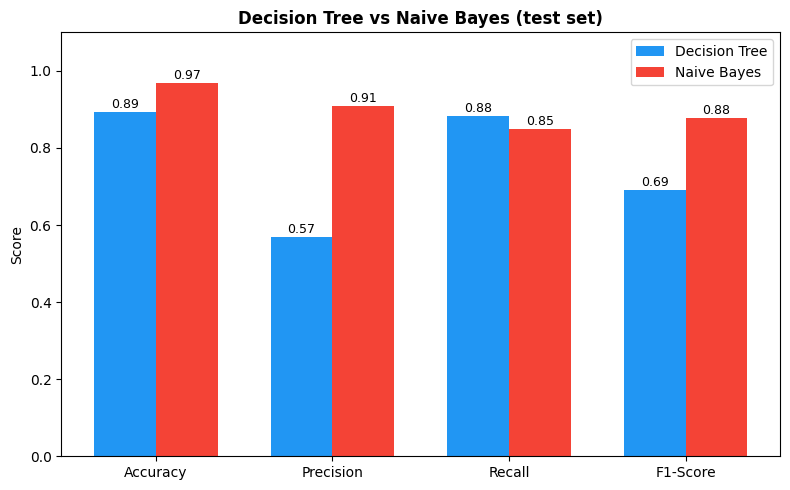

In [14]:
# Write your code here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {'Decision Tree': y_pred_dt, 'Naive Bayes': y_pred_nb}

rows = []
for name, y_pred in models.items():
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
    })

metrics_df = pd.DataFrame(rows)
print(metrics_df.round(3).to_string(index=False))

# Grouped bar chart: four metrics, one group per metric, one bar per model
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars_dt = ax.bar(x - width/2, metrics_df.loc[0, metric_names], width,
                 label='Decision Tree', color='#2196F3')
bars_nb = ax.bar(x + width/2, metrics_df.loc[1, metric_names], width,
                 label='Naive Bayes', color='#F44336')

for bars in (bars_dt, bars_nb):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                f'{b.get_height():.2f}', ha='center', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Decision Tree vs Naive Bayes (test set)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


### Step 6C — Cross-Validation

**Hint:**
- Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`
- Run `cross_val_score` with `scoring='f1'` for both models
- Print the average F1 across 5 folds for each model


In [15]:
# Write your code here
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import BernoulliNB

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

dt_cv = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')
nb_cv = BernoulliNB()

dt_scores = cross_val_score(dt_cv, X, y, cv=cv, scoring='f1')
nb_scores = cross_val_score(nb_cv, X, y, cv=cv, scoring='f1')

print('5-fold cross-validated F1:')
print(f'  Decision Tree: {dt_scores.mean():.3f}  (folds: {np.round(dt_scores, 3)})')
print(f'  Naive Bayes  : {nb_scores.mean():.3f}  (folds: {np.round(nb_scores, 3)})')

5-fold cross-validated F1:
  Decision Tree: 0.832  (folds: [0.861 0.84  0.825 0.806 0.828])
  Naive Bayes  : 0.872  (folds: [0.867 0.863 0.894 0.853 0.881])


### Q6 — Evaluation & Analysis *(25 points)*

> **Points breakdown:**
> - Step 6A code (runs correctly): 4 pts
> - Step 6B code (runs correctly): 4 pts
> - Step 6C code (runs correctly): 4 pts
> - Q6a written: 3 pts
> - Q6b written: 3 pts
> - Q6c written: 4 pts
> - Q6d written: 3 pts
> - **Total: 25 pts**

---

**Q6a. Read the confusion matrices (Step 6A) — *(3 points)***

For each model, state:
- How many spam messages were correctly caught (True Positives)?
- How many spam messages slipped through (False Negatives)?
- How many legitimate messages were wrongly blocked (False Positives)?

Decision Tree: The tree correctly caught 165 spam messages (True Positives) and let 22 spam messages slip through (False Negatives). It also wrongly blocked 125 legitimate messages (False Positives), out of 1,206 ham messages in the test set. Its class weighting makes it aggressive about flagging spam, which keeps FN low but produces many false alarms.

Naive Bayes: Naive Bayes correctly caught 159 spam messages and let 28 spam messages through. It wrongly blocked only 16 legitimate messages. It catches slightly fewer spam messages than the tree (6 fewer), but it blocks far fewer real messages (109 fewer).

**Q6b. Apply your metric from Q1b — *(3 points)***

Which model wins on the metric you chose in Step 1?
By how much? Does the cross-validation result (Step 6C) confirm this?

*Your answer:*
My primary metric from Q1b was Precision, because blocking a legitimate message is the costlier error. Naive Bayes wins clearly, with a precision of 0.909 versus 0.569 for the Decision Tree, a difference of about 0.34. In practice, roughly 91% of the messages Naive Bayes blocks are really spam, compared with only 57% for the tree. The 5-fold cross-validation confirms the overall picture: Naive Bayes averaged an F1 of 0.872 versus 0.832 for the Decision Tree, and it was higher in every fold. Naive Bayes also held its test-set F1 (0.878) almost exactly under cross-validation, so the result is representative. The tree’s recall (0.882 vs 0.850) is slightly higher, but that small edge does not make up for its poor precision.

**Q6c. Recommendation memo — *(4 points)***

Imagine you are presenting to a product manager at a mobile carrier.
Write 4–5 sentences that:
1. State which model you recommend
2. Justify the choice with one specific number from your results
3. Acknowledge one weakness of your recommended model
4. Propose one concrete improvement

*Your memo:*
> I recommend Naive Bayes for deployment because it reaches a precision of 0.909 and wrongly blocks only 16 of 1,206 legitimate messages, compared with 125 for the Decision Tree, which protects users from losing things like verification codes and appointment reminders. Its weakness is that it still lets 28 spam messages through (recall of 0.850), and because it relies on simple surface features it would struggle with spam written in calm, professional language. To improve it, I would add word-based features such as TF-IDF or a URL reputation check, and retrain regularly on recent messages so the model keeps up with current spam patterns. I would also add a user feedback option for reporting missed spam and wrongly blocked messages.

**Q6d. Generalization — *(3 points)***

The SMS Spam Collection was collected in the early 2010s.
Modern spam often uses professional language and legitimate-looking URLs.
Identify **two features you built** that would likely fail on modern spam, and explain why.

*Your answer:*
> Two features likely to fail on modern spam are has_all_caps and has_call_to_action. The ALL CAPS feature fails because modern spam and phishing often copy legitimate companies, using polished, normally capitalized wording such as “Your account requires verification,” so there are no shouted words to detect. The call-to-action feature fails because it depends on a short list of words like “txt”, “reply”, and “call”, which were typical of 2010s premium-number scams. Modern spam usually asks people to click a link and can phrase this in many ways without those exact words, so the feature would stay at 0 even for real spam.
